# Desigualdade socioeconômica e acesso ao ensino superior – ENEM 2023

A nota do ENEM é o que define a entrada pelo SiSU, ProUni e FIES. A ideia aqui é ver se renda, escolaridade dos pais, tipo de escola e acesso à internet estão ligados à nota de Matemática e à presença na prova. O dataset não diz quem entrou na faculdade, então usamos nota e presença como indicadores de acesso.

Perguntas:
1. Escola privada tira nota maior que pública? Quanto?
2. A nota muda entre faixas de renda?
3. Quanto da nota é explicado pelo perfil socioeconômico?
4. Internet em casa faz diferença entre alunos de mesma renda?
5. A diferença pública x privada continua entre alunos de mesma renda?
6. Os mais pobres faltam mais?

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as sts
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.proportion import proportion_confint
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid")
SEMENTE = 42

## Dados

Carregamos só as colunas que vamos usar. Respostas, gabaritos e códigos de prova ficaram de fora.

In [2]:
colunas = [
    "TP_FAIXA_ETARIA", "TP_SEXO", "TP_COR_RACA", "TP_ST_CONCLUSAO", "TP_ESCOLA", "IN_TREINEIRO", "SG_UF_PROVA",
    "TP_PRESENCA_CN", "TP_PRESENCA_CH", "TP_PRESENCA_LC", "TP_PRESENCA_MT",
    "NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_MT", "NU_NOTA_REDACAO",
    "Q001", "Q002", "Q005", "Q006", "Q025",
]

df = pd.read_csv("data/MICRODADOS_ENEM_2023.csv", sep=";", encoding="latin-1", usecols=colunas)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3933955 entries, 0 to 3933954
Data columns (total 21 columns):
 #   Column           Dtype  
---  ------           -----  
 0   TP_FAIXA_ETARIA  int64  
 1   TP_SEXO          object 
 2   TP_COR_RACA      int64  
 3   TP_ST_CONCLUSAO  int64  
 4   TP_ESCOLA        int64  
 5   IN_TREINEIRO     int64  
 6   SG_UF_PROVA      object 
 7   TP_PRESENCA_CN   int64  
 8   TP_PRESENCA_CH   int64  
 9   TP_PRESENCA_LC   int64  
 10  TP_PRESENCA_MT   int64  
 11  NU_NOTA_CN       float64
 12  NU_NOTA_CH       float64
 13  NU_NOTA_LC       float64
 14  NU_NOTA_MT       float64
 15  NU_NOTA_REDACAO  float64
 16  Q001             object 
 17  Q002             object 
 18  Q005             int64  
 19  Q006             object 
 20  Q025             object 
dtypes: float64(5), int64(10), object(6)
memory usage: 630.3+ MB


O tipo de escola só é informado para quem conclui o ensino médio em 2023. Para os outros vem sempre "não respondeu".

In [3]:
pd.crosstab(df.TP_ST_CONCLUSAO, df.TP_ESCOLA)

TP_ESCOLA,1,2,3
TP_ST_CONCLUSAO,,,
1,1895301,0,0
2,5,1166540,234619
3,620067,0,0
4,17423,0,0


Por isso a população do estudo são os concluintes de 2023. Isso também tira os treineiros, que estão todos na situação 3.

In [4]:
pop = df[(df.TP_ST_CONCLUSAO == 2) & (df.TP_ESCOLA != 1)].copy()
del df
len(pop)

1401159

## Ausentes e inconsistências

As notas vazias são de quem faltou ou foi eliminado.

In [5]:
presencas = ["TP_PRESENCA_LC", "TP_PRESENCA_CH", "TP_PRESENCA_CN", "TP_PRESENCA_MT"]
display(pop.isna().sum()[lambda s: s > 0])
pop[presencas].apply(pd.Series.value_counts)

NU_NOTA_CN         346015
NU_NOTA_CH         301547
NU_NOTA_LC         301547
NU_NOTA_MT         346015
NU_NOTA_REDACAO    301547
dtype: int64

,TP_PRESENCA_LC,TP_PRESENCA_CH,TP_PRESENCA_CN,TP_PRESENCA_MT
1,1099612,1099612,1055144,1055144
0,299860,299860,345199,345199
2,1687,1687,816,816


Não faz sentido imputar nota de quem não fez a prova. Eliminados saem da base (menos de 0,2%) e os faltosos viram a variável `faltou`, usada na pergunta 6.

In [6]:
pop = pop[~(pop[presencas] == 2).any(axis=1)].copy()
pop["faltou"] = ((pop.TP_PRESENCA_LC == 0) | (pop.TP_PRESENCA_MT == 0)).astype(int)
pop.faltou.mean()

np.float64(0.2486658620847442)

Alguns presentes têm nota zero em Matemática. Eles também zeram Ciências da Natureza, que é no mesmo dia, então é prova não respondida. Ficam fora das análises de nota.

In [7]:
zeros = pop[(pop.faltou == 0) & (pop.NU_NOTA_MT == 0)]
len(zeros), zeros[["NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC"]].median().to_dict()

(5486, {'NU_NOTA_CN': 0.0, 'NU_NOTA_CH': 462.05, 'NU_NOTA_LC': 473.0})

Na escolaridade dos pais, a opção "H – Não sei" funciona como ausente. É bem mais comum para o pai do que para a mãe, então apagar essas linhas tiraria principalmente famílias sem pai presente.

In [8]:
(pop.Q001 == 'H').mean(), (pop.Q002 == 'H').mean(), ((pop.Q001 == 'H') & (pop.Q002 == 'H')).mean()

(np.float64(0.12471687105335408),
 np.float64(0.050148142216527865),
 np.float64(0.03705986318294134))

## Novas variáveis

- renda per capita: ponto médio da faixa de renda (Q006) dividido pelo número de moradores (Q005), depois convertida em salários mínimos (R$ 1.320) e em 5 faixas. A faixa aberta (acima de R$ 26.400) recebeu 1,25x o limite.
- escolaridade dos pais: anos de estudo aproximados, usando o maior entre pai e mãe. Se os dois forem "não sei", usamos a mediana da mesma faixa de renda.
- atraso: concluinte com 19 anos ou mais.

In [9]:
SM = 1320
renda = {"A": 0, "B": 660, "C": 1650, "D": 2310, "E": 2970, "F": 3630, "G": 4620, "H": 5940, "I": 7260,
         "J": 8580, "K": 9900, "L": 11220, "M": 12540, "N": 14520, "O": 17820, "P": 23100, "Q": 26400 * 1.25}
faixas = ["Até 1/4 SM", "1/4 a 1/2 SM", "1/2 a 1 SM", "1 a 2 SM", "Acima de 2 SM"]

pop["renda_familiar"] = pop.Q006.map(renda)
pop["renda_pc"] = pop.renda_familiar / pop.Q005
pop["renda_pc_sm"] = pop.renda_pc / SM
pop["faixa_renda"] = pd.cut(pop.renda_pc_sm, [0, 0.25, 0.5, 1, 2, np.inf], labels=faixas, include_lowest=True)

anos = {"A": 0, "B": 2, "C": 6, "D": 10, "E": 12, "F": 16, "G": 18, "H": np.nan}
pop["escol_pais"] = pop[["Q001", "Q002"]].apply(lambda s: s.map(anos)).max(axis=1)
pop["escol_pais_imputada"] = pop.escol_pais.isna().astype(int)
pop["escol_pais"] = pop.escol_pais.fillna(pop.groupby("Q006").escol_pais.transform("median"))

regioes = {"Norte": "AC AM AP PA RO RR TO", "Nordeste": "AL BA CE MA PB PE PI RN SE",
           "Centro-Oeste": "DF GO MS MT", "Sudeste": "ES MG RJ SP", "Sul": "PR RS SC"}
uf_regiao = {uf: r for r, ufs in regioes.items() for uf in ufs.split()}
cores = {0: "Não declarado", 1: "Branca", 2: "Preta", 3: "Parda", 4: "Amarela", 5: "Indígena"}

pop["regiao"] = pop.SG_UF_PROVA.map(uf_regiao)
pop["cor"] = pop.TP_COR_RACA.map(cores)
pop["internet"] = (pop.Q025 == "B").astype(int)
pop["privada"] = (pop.TP_ESCOLA == 3).astype(int)
pop["escola"] = pop.privada.map({0: "Pública", 1: "Privada"})
pop["feminino"] = (pop.TP_SEXO == "F").astype(int)
pop["atraso"] = (pop.TP_FAIXA_ETARIA >= 4).astype(int)
pop["media_geral"] = pop[["NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_MT", "NU_NOTA_REDACAO"]].mean(axis=1)

notas_pop = pop[(pop.faltou == 0) & (pop.NU_NOTA_MT > 0)].copy()
len(pop), len(notas_pop), pop.faixa_renda.value_counts(normalize=True).sort_index().round(3).to_dict()

(1398656,
 1045372,
 {'Até 1/4 SM': 0.431,
  '1/4 a 1/2 SM': 0.187,
  '1/2 a 1 SM': 0.202,
  '1 a 2 SM': 0.106,
  'Acima de 2 SM': 0.074})

## Amostra

Temos a população inteira, mas os testes e ICs são feitos numa amostra aleatória de 10 mil inscritos. Assim dá pra conferir se as estimativas acertam o valor real. Com mais de 1 milhão de linhas qualquer diferença daria significativa, então também olhamos o tamanho do efeito.

In [10]:
amostra = pop.sample(n=10_000, random_state=SEMENTE)
notas_am = amostra[(amostra.faltou == 0) & (amostra.NU_NOTA_MT > 0)].copy()

pd.DataFrame({
    "pop": [pop.privada.mean(), pop.internet.mean(), pop.faltou.mean(), notas_pop.NU_NOTA_MT.mean()],
    "amostra": [amostra.privada.mean(), amostra.internet.mean(), amostra.faltou.mean(), notas_am.NU_NOTA_MT.mean()],
}, index=["privada", "internet", "faltou", "media_mt"])

,pop,amostra
privada,0.168,0.165
internet,0.906,0.906
faltou,0.249,0.245
media_mt,533.720,535.171


## Exploração

In [11]:
notas_pop[['NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT', 'NU_NOTA_REDACAO']].describe().T

,count,mean,std,min,25%,50%,75%,max
NU_NOTA_CN,1045372.000,491.993,77.199,0.000,436.100,487.800,544.500,868.400
NU_NOTA_CH,1045372.000,519.299,84.836,0.000,464.900,525.800,579.000,823.000
NU_NOTA_LC,1045372.000,515.169,73.272,0.000,469.300,520.300,566.500,820.800
NU_NOTA_MT,1045372.000,533.720,123.144,322.100,431.200,521.200,626.100,958.600
NU_NOTA_REDACAO,1045372.000,631.500,213.973,0.000,520.000,640.000,800.000,1000.000


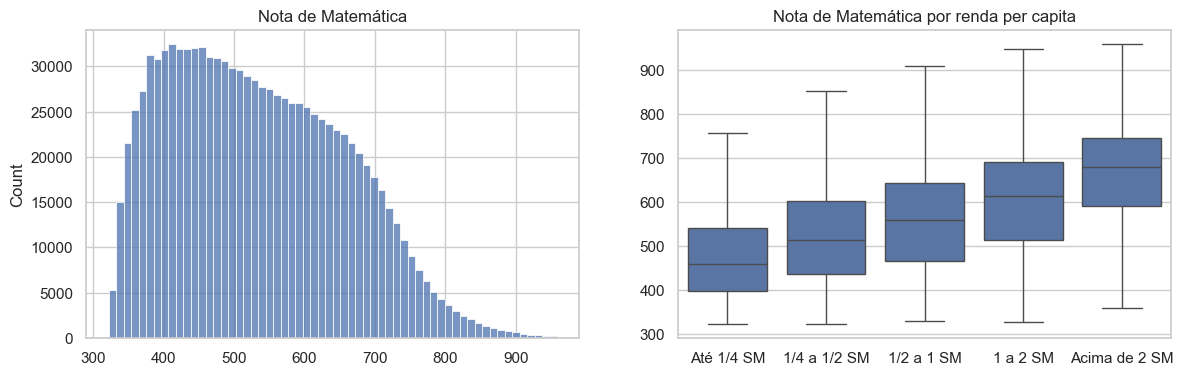

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(notas_pop.NU_NOTA_MT, bins=60, ax=ax[0])
ax[0].set(title="Nota de Matemática", xlabel="")
sns.boxplot(data=notas_pop, x="faixa_renda", y="NU_NOTA_MT", showfliers=False, ax=ax[1])
ax[1].set(title="Nota de Matemática por renda per capita", xlabel="", ylabel="")
plt.show()

Comparando escola e internet dentro de cada faixa de renda:

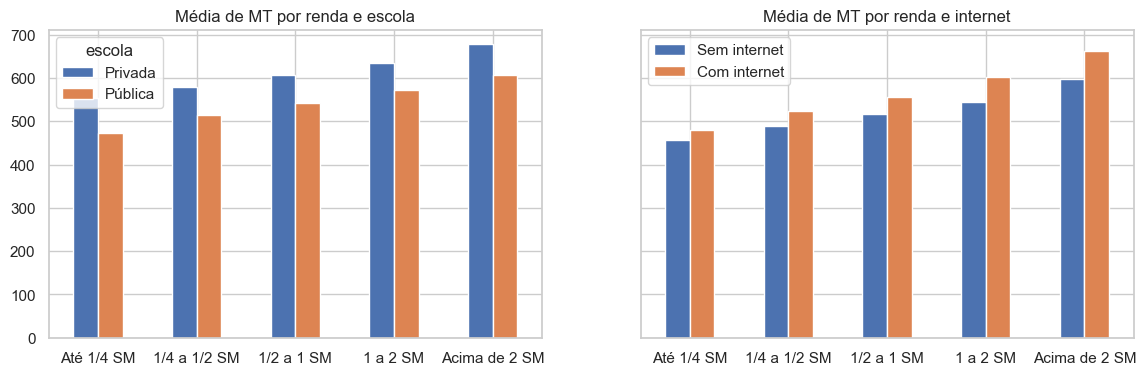

,Privada,Pública,Sem internet,Com internet,tem_internet
faixa_renda,,,,,
Até 1/4 SM,552.928,473.552,457.536,480.399,0.822
1/4 a 1/2 SM,579.250,514.698,488.894,522.620,0.959
1/2 a 1 SM,605.689,541.438,516.875,556.901,0.986
1 a 2 SM,634.400,571.305,544.471,601.738,0.995
Acima de 2 SM,677.248,606.340,596.483,662.503,0.998


In [13]:
escola_renda = notas_pop.groupby(["faixa_renda", "escola"], observed=True).NU_NOTA_MT.mean().unstack()
internet_renda = notas_pop.groupby(["faixa_renda", "internet"], observed=True).NU_NOTA_MT.mean().unstack()
internet_renda.columns = ["Sem internet", "Com internet"]

fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
escola_renda.plot(kind="bar", rot=0, ax=ax[0], title="Média de MT por renda e escola", xlabel="")
internet_renda.plot(kind="bar", rot=0, ax=ax[1], title="Média de MT por renda e internet", xlabel="")
plt.show()

pd.concat([escola_renda, internet_renda, notas_pop.groupby("faixa_renda", observed=True).internet.mean().rename("tem_internet")], axis=1)

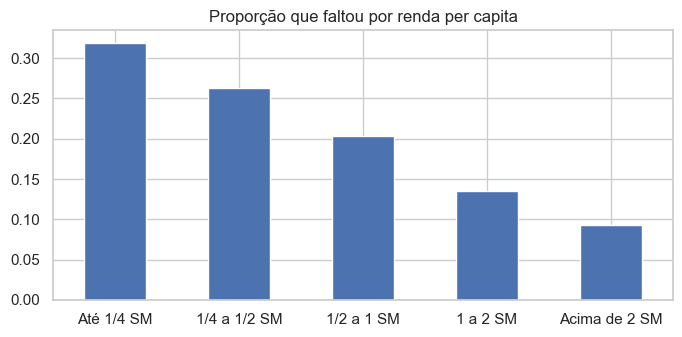

faixa_renda
Até 1/4 SM      0.319
1/4 a 1/2 SM    0.263
1/2 a 1 SM      0.203
1 a 2 SM        0.135
Acima de 2 SM   0.092
Name: faltou, dtype: float64

In [14]:
faltas = pop.groupby("faixa_renda", observed=True).faltou.mean()
faltas.plot(kind="bar", rot=0, figsize=(8, 3.5), title="Proporção que faltou por renda per capita", xlabel="")
plt.show()
faltas

Spearman porque boa parte das variáveis é binária ou ordinal e a renda é bem assimétrica.

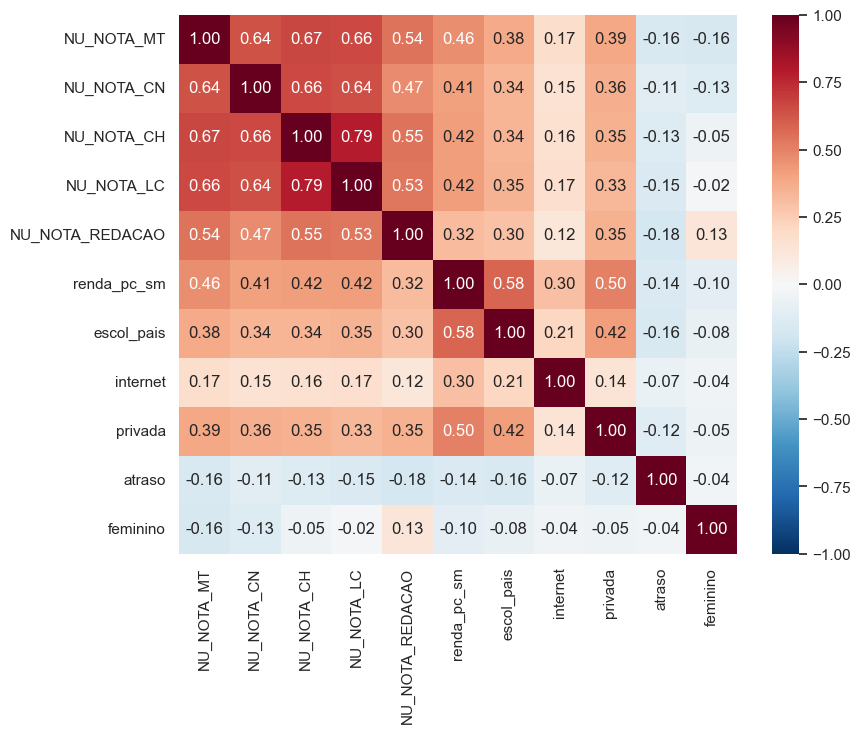

In [15]:
vars_corr = ["NU_NOTA_MT", "NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_REDACAO",
             "renda_pc_sm", "escol_pais", "internet", "privada", "atraso", "feminino"]
plt.figure(figsize=(9, 7))
sns.heatmap(notas_pop[vars_corr].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.show()

## Testes de hipótese e intervalos de confiança

α = 0,05 em tudo. IC da média com t de Student (n − 1 gl), já que o desvio populacional é desconhecido.

In [16]:
def ic_media(x, conf=0.95):
    x = np.asarray(x)
    n, m = len(x), x.mean()
    e = sts.t.ppf((1 + conf) / 2, n - 1) * x.std(ddof=1) / np.sqrt(n)
    return pd.Series({"n": n, "gl": n - 1, "media": m, "ic_inf": m - e, "ic_sup": m + e})


mu = notas_pop.NU_NOTA_MT.mean()
ic_media(notas_am.NU_NOTA_MT).to_dict(), mu

({'n': 7523.0,
  'gl': 7522.0,
  'media': 535.1708095174797,
  'ic_inf': 532.378304455759,
  'ic_sup': 537.9633145792004},
 np.float64(533.7197209223128))

Teste rápido do que significa 95%: em 1.000 amostras de 500 alunos, quantos ICs pegam a média real?

In [17]:
rng = np.random.default_rng(SEMENTE)
mt = notas_pop.NU_NOTA_MT.to_numpy()
sim = pd.DataFrame([ic_media(rng.choice(mt, 500)) for _ in range(1000)])
((sim.ic_inf <= mu) & (mu <= sim.ic_sup)).mean()

np.float64(0.964)

### 1. Pública x privada

H0: médias iguais. H1: médias diferentes. O Levene rejeita variâncias iguais, então usamos o t de Welch. Tamanho do efeito pelo d de Cohen.

In [18]:
def comparar(a, b):
    t = sts.ttest_ind(a, b, equal_var=False)
    ic = t.confidence_interval()
    d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
    return pd.Series({"n_a": len(a), "n_b": len(b), "dif": a.mean() - b.mean(), "ic_inf": ic.low,
                      "ic_sup": ic.high, "t": t.statistic, "gl": t.df, "p": t.pvalue, "d": d})


priv = notas_am.loc[notas_am.privada == 1, "NU_NOTA_MT"]
publ = notas_am.loc[notas_am.privada == 0, "NU_NOTA_MT"]
dif_pop = notas_pop.groupby("privada").NU_NOTA_MT.mean().diff().iloc[-1]

display(sts.levene(priv, publ))
comparar(priv, publ).to_frame("privada - publica").T.assign(dif_pop=dif_pop)

LeveneResult(statistic=np.float64(13.384337043051913), pvalue=np.float64(0.00025546973141334734))

,n_a,n_b,dif,ic_inf,ic_sup,t,gl,p,d,dif_pop
privada - publica,1557.000,5966.000,121.135,114.454,127.816,35.555,2275.988,0.000,1.039,124.571


### 2. Nota por faixa de renda

ANOVA com k − 1 e n − k gl. Como o Levene também rejeita aqui, conferimos com Alexander-Govern, que aguenta variâncias diferentes. Depois Tukey para ver quais faixas diferem.

In [19]:
grupos = [g.NU_NOTA_MT.to_numpy() for _, g in notas_am.groupby("faixa_renda", observed=True)]
k, n = len(grupos), sum(len(g) for g in grupos)
m = notas_am.NU_NOTA_MT.mean()
eta2 = sum(len(g) * (g.mean() - m) ** 2 for g in grupos) / ((notas_am.NU_NOTA_MT - m) ** 2).sum()

anova = sts.f_oneway(*grupos)
pd.Series({"levene_p": sts.levene(*grupos).pvalue, "F": anova.statistic, "gl_entre": k - 1, "gl_dentro": n - k,
           "p": anova.pvalue, "p_alexander_govern": sts.alexandergovern(*grupos).pvalue, "eta2": eta2})

levene_p                0.000
F                     609.089
gl_entre                4.000
gl_dentro            7518.000
p                       0.000
p_alexander_govern      0.000
eta2                    0.245
dtype: float64

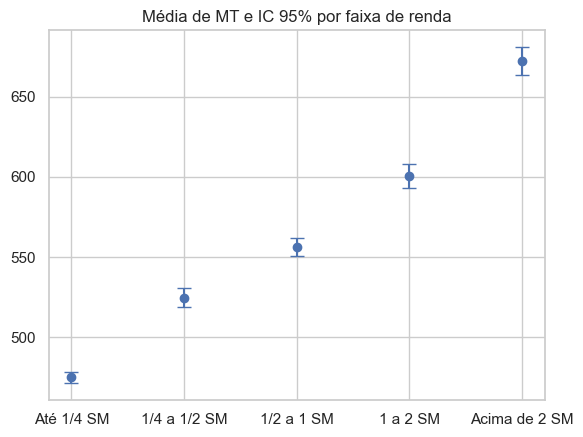

         Multiple Comparison of Means - Tukey HSD, FWER=0.05          
    group1        group2     meandiff p-adj   lower     upper   reject
----------------------------------------------------------------------
     1 a 2 SM    1/2 a 1 SM   -44.245   0.0   -56.281  -32.2091   True
     1 a 2 SM  1/4 a 1/2 SM  -75.7317   0.0  -88.1261  -63.3373   True
     1 a 2 SM Acima de 2 SM   71.8654   0.0   57.0982   86.6325   True
     1 a 2 SM    Até 1/4 SM -125.4383   0.0 -136.4807 -114.3959   True
   1/2 a 1 SM  1/4 a 1/2 SM  -31.4866   0.0  -42.1728  -20.8005   True
   1/2 a 1 SM Acima de 2 SM  116.1104   0.0  102.7447  129.4761   True
   1/2 a 1 SM    Até 1/4 SM  -81.1933   0.0  -90.2766  -72.1099   True
 1/4 a 1/2 SM Acima de 2 SM  147.5971   0.0  133.9077  161.2864   True
 1/4 a 1/2 SM    Até 1/4 SM  -49.7066   0.0  -59.2598  -40.1535   True
Acima de 2 SM    Até 1/4 SM -197.3037   0.0 -209.7821 -184.8252   True
----------------------------------------------------------------------


In [20]:
ic_renda = notas_am.groupby("faixa_renda", observed=True).NU_NOTA_MT.apply(ic_media).unstack()
plt.errorbar(ic_renda.index.astype(str), ic_renda.media, yerr=ic_renda.media - ic_renda.ic_inf, fmt="o", capsize=5)
plt.title("Média de MT e IC 95% por faixa de renda")
plt.show()

print(pairwise_tukeyhsd(notas_am.NU_NOTA_MT, notas_am.faixa_renda.astype(str)))

### 4 e 5. Internet e escola dentro da mesma faixa de renda

Quem tem internet ou estuda em escola privada costuma ter renda maior, então comparamos dentro de cada faixa. São 5 testes por variável, então usamos Bonferroni (p < 0,01).

In [21]:
def comparar_por_faixa(dados, col):
    res = {}
    for faixa, g in dados.groupby("faixa_renda", observed=True):
        a, b = g.loc[g[col] == 1, "NU_NOTA_MT"], g.loc[g[col] == 0, "NU_NOTA_MT"]
        if len(a) > 1 and len(b) > 1:
            res[faixa] = comparar(a, b)
    res = pd.DataFrame(res).T
    res["sig_bonferroni"] = res.p < 0.05 / len(res)
    return res


comparar_por_faixa(notas_am, "internet")

,n_a,n_b,dif,ic_inf,ic_sup,t,gl,p,d,sig_bonferroni
Até 1/4 SM,2360.000,523.000,21.948,13.277,30.620,4.968,821.845,0.000,0.233,True
1/4 a 1/2 SM,1349.000,48.000,51.021,18.749,83.294,3.175,50.534,0.003,0.462,True
1/2 a 1 SM,1602.000,27.000,14.032,-25.975,54.040,0.720,27.113,0.478,0.132,False
1 a 2 SM,924.000,8.000,97.054,7.191,186.917,2.544,7.140,0.038,0.871,False


A faixa acima de 2 SM não aparece porque quase ninguém dela está sem internet. Nas faixas altas o grupo sem internet é pequeno e o IC fica largo.

In [22]:
comparar_por_faixa(notas_am, 'privada')

,n_a,n_b,dif,ic_inf,ic_sup,t,gl,p,d,sig_bonferroni
Até 1/4 SM,91.000,2792.000,61.998,39.456,84.541,5.460,94.800,0.000,0.610,True
1/4 a 1/2 SM,140.000,1257.000,58.652,38.388,78.917,5.714,167.993,0.000,0.520,True
1/2 a 1 SM,339.000,1290.000,54.294,40.768,67.820,7.886,513.079,0.000,0.487,True
1 a 2 SM,443.000,489.000,55.731,41.282,70.181,7.570,919.318,0.000,0.497,True
Acima de 2 SM,544.000,138.000,50.836,29.455,72.218,4.687,214.205,0.000,0.445,True


### 6. Faltas por faixa de renda

Qui-quadrado de independência, gl = (linhas − 1)(colunas − 1). Efeito pelo V de Cramér. IC das proporções pelo método de Wilson.

In [23]:
tab = pd.crosstab(amostra.faixa_renda, amostra.faltou)
qui2 = sts.chi2_contingency(tab)
v = np.sqrt(qui2.statistic / (tab.to_numpy().sum() * (min(tab.shape) - 1)))
display(pd.Series({"qui2": qui2.statistic, "gl": qui2.dof, "p": qui2.pvalue, "v_cramer": v, "menor_esperada": qui2.expected_freq.min()}))

cont = amostra.groupby("faixa_renda", observed=True).faltou.agg(["sum", "count"])
lo, hi = proportion_confint(cont["sum"], cont["count"], method="wilson")
ic_faltas = pd.DataFrame({"prop": cont["sum"] / cont["count"], "ic_inf": lo, "ic_sup": hi, "prop_pop": faltas})
ic_faltas["pop_no_ic"] = ic_faltas.prop_pop.between(ic_faltas.ic_inf, ic_faltas.ic_sup)
ic_faltas

qui2             390.312
gl                 4.000
p                  0.000
v_cramer           0.198
menor_esperada   183.655
dtype: float64

,prop,ic_inf,ic_sup,prop_pop,pop_no_ic
faixa_renda,,,,,
Até 1/4 SM,0.331,0.317,0.345,0.319,True
1/4 a 1/2 SM,0.242,0.223,0.262,0.263,False
1/2 a 1 SM,0.179,0.163,0.196,0.203,False
1 a 2 SM,0.135,0.116,0.157,0.135,True
Acima de 2 SM,0.089,0.071,0.112,0.092,True


Duas faixas ficaram fora do IC. Rodando com 200 sementes diferentes, cada faixa fica fora em 2,5% a 6,5% das vezes, perto dos 5% esperados. Foi azar dessa amostra.

## Regressão linear

Primeiro uma simples, nota x escolaridade dos pais.

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    401.4517      3.935    102.009      0.000     393.737     409.166
escol_pais    10.9271      0.303     36.052      0.000      10.333      11.521
R² = 0.147


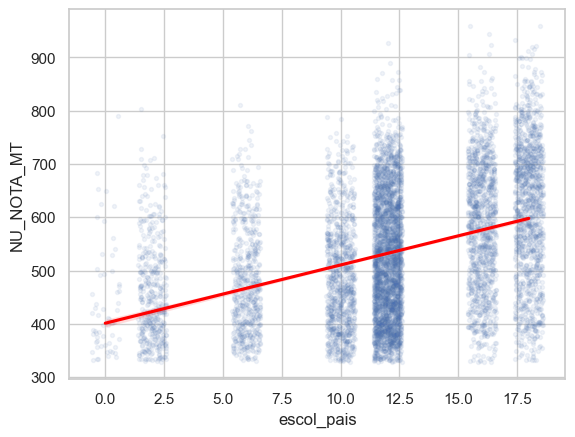

In [24]:
simples = smf.ols("NU_NOTA_MT ~ escol_pais", data=notas_am).fit()
print(simples.summary().tables[1])
print(f"R² = {simples.rsquared:.3f}")

sns.regplot(data=notas_am, x="escol_pais", y="NU_NOTA_MT", x_jitter=0.6, scatter_kws={"alpha": 0.08, "s": 8}, line_kws={"color": "red"})
plt.show()

Agora a múltipla. Renda entra em faixas porque a relação não é linear e a faixa "sem renda" impede usar log. Categóricas viram dummies, com referência em "Até 1/4 SM", Sudeste e Branca. Separamos 80/20 para treino e teste. Erros-padrão HC3 por causa da heterocedasticidade (Breusch-Pagan logo abaixo).

In [25]:
formula = ("NU_NOTA_MT ~ C(faixa_renda) + escol_pais + internet + privada + C(regiao, Treatment('Sudeste'))"
           " + feminino + C(cor, Treatment('Branca')) + atraso")

treino, teste = train_test_split(notas_am, test_size=0.2, random_state=SEMENTE)
modelo = smf.ols(formula, data=treino).fit(cov_type="HC3")
modelo.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             NU_NOTA_MT   R-squared:                       0.325
Model:                            OLS   Adj. R-squared:                  0.323
Method:                 Least Squares   F-statistic:                     170.6
Date:                Sun, 04 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:32:08   Log-Likelihood:                -36374.
No. Observations:                6018   AIC:                         7.279e+04
Df Residuals:                    5999   BIC:                         7.291e+04
Df Model:                          18                                         
Covariance Type:                  HC3                                         
===================================================================================================================
                                                      coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------
Intercept                                         476.1139      6.613     71.996      0.000     463.153     489.075
C(faixa_renda)[T.1/4 a 1/2 SM]                     26.6511      3.968      6.716      0.000      18.873      34.429
C(faixa_renda)[T.1/2 a 1 SM]                       41.9560      4.134     10.150      0.000      33.854      50.058
C(faixa_renda)[T.1 a 2 SM]                         64.9146      5.531     11.737      0.000      54.075      75.755
C(faixa_renda)[T.Acima de 2 SM]                   110.5056      6.761     16.345      0.000      97.255     123.757
C(regiao, Treatment('Sudeste'))[T.Centro-Oeste]   -16.7208      4.893     -3.418      0.001     -26.310      -7.132
C(regiao, Treatment('Sudeste'))[T.Nordeste]        -4.9585      3.611     -1.373      0.170     -12.035       2.118
C(regiao, Treatment('Sudeste'))[T.Norte]          -26.4193      4.694     -5.628      0.000     -35.620     -17.219
C(regiao, Treatment('Sudeste'))[T.Sul]             -7.4387      4.357     -1.707      0.088     -15.978       1.101
C(cor, Treatment('Branca'))[T.Amarela]             -4.1603     10.273     -0.405      0.686     -24.296      15.975
C(cor, Treatment('Branca'))[T.Indígena]           -51.5988     19.917     -2.591      0.010     -90.636     -12.561
C(cor, Treatment('Branca'))[T.Não declarado]      -42.7711     16.998     -2.516      0.012     -76.088      -9.455
C(cor, Treatment('Branca'))[T.Parda]              -22.3436      3.164     -7.062      0.000     -28.545     -16.142
C(cor, Treatment('Branca'))[T.Preta]              -34.2674      4.454     -7.694      0.000     -42.996     -25.538
escol_pais                                          3.9206      0.358     10.967      0.000       3.220       4.621
internet                                           13.7763      4.606      2.991      0.003       4.748      22.805
privada                                            44.8823      4.377     10.255      0.000      36.304      53.460
feminino                                          -32.5374      2.777    -11.715      0.000     -37.981     -27.094
atraso                                            -29.2671      4.206     -6.959      0.000     -37.510     -21.024
==============================================================================
Omnibus:                       53.158   Durbin-Watson:                   2.035
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               42.242
Skew:                           0.127   Prob(JB):                     6.72e-10
Kurtosis:                       2.677   Cond. No.                         188.
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust

Pressupostos: resíduos, normalidade, homocedasticidade e multicolinearidade.

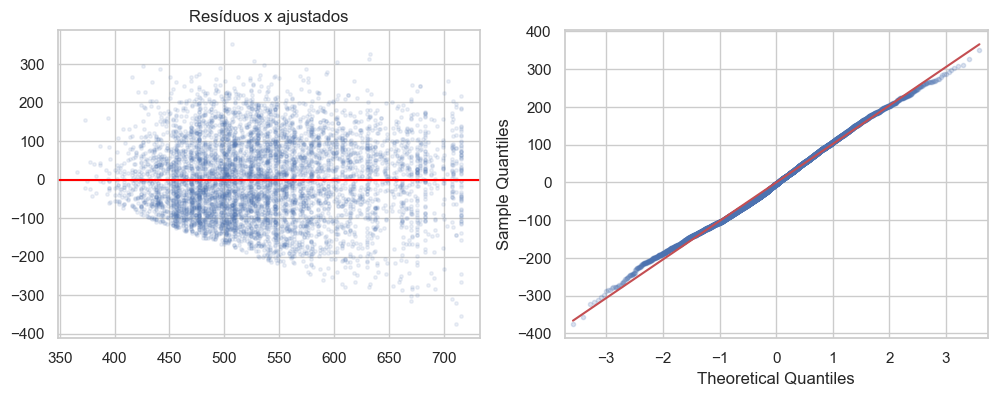

Breusch-Pagan p = 2.291547842782627e-25
VIF máximo = 2.0


In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(modelo.fittedvalues, modelo.resid, alpha=0.1, s=6)
ax[0].axhline(0, color="red")
ax[0].set(title="Resíduos x ajustados")
sm.qqplot(modelo.resid, line="s", ax=ax[1], alpha=0.2, markersize=3)
plt.show()

x = pd.DataFrame(modelo.model.exog, columns=modelo.model.exog_names)
vif = pd.Series([variance_inflation_factor(x.values, i) for i in range(1, x.shape[1])], index=x.columns[1:])
print("Breusch-Pagan p =", het_breuschpagan(modelo.resid, modelo.model.exog)[1])
print("VIF máximo =", round(vif.max(), 2))

O limite diagonal embaixo no gráfico de resíduos vem do piso da TRI (a menor nota de MT é por volta de 322).

Desempenho no treino, no teste, no resto da população e contra um modelo que chuta sempre a média.

In [27]:
fora = notas_pop.drop(index=amostra.index, errors="ignore")


def avaliar(y, y_prev):
    return pd.Series({"R2": r2_score(y, y_prev), "RMSE": np.sqrt(mean_squared_error(y, y_prev)), "MAE": mean_absolute_error(y, y_prev)})


metricas = pd.DataFrame({
    "treino": avaliar(treino.NU_NOTA_MT, modelo.predict(treino)),
    "teste": avaliar(teste.NU_NOTA_MT, modelo.predict(teste)),
    "pop_fora_amostra": avaliar(fora.NU_NOTA_MT, modelo.predict(fora)),
    "so_media": avaliar(teste.NU_NOTA_MT, np.full(len(teste), treino.NU_NOTA_MT.mean())),
}).T
metricas

,R2,RMSE,MAE
treino,0.325,102.027,83.419
teste,0.288,102.059,82.426
pop_fora_amostra,0.306,102.573,83.609
so_media,-0.001,121.027,102.534


Comparando os coeficientes da amostra com o mesmo modelo rodado na população inteira:

In [28]:
modelo_pop = smf.ols(formula, data=notas_pop).fit()
ic = modelo.conf_int()
coef = pd.DataFrame({"coef": modelo.params, "ic_inf": ic[0], "ic_sup": ic[1], "p": modelo.pvalues, "coef_pop": modelo_pop.params})
coef["pop_no_ic"] = coef.coef_pop.between(coef.ic_inf, coef.ic_sup)
coef

,coef,ic_inf,ic_sup,p,coef_pop,pop_no_ic
Intercept,476.114,463.153,489.075,0.000,486.676,True
C(faixa_renda)[T.1/4 a 1/2 SM],26.651,18.873,34.429,0.000,24.282,True
C(faixa_renda)[T.1/2 a 1 SM],41.956,33.854,50.058,0.000,41.200,True
C(faixa_renda)[T.1 a 2 SM],64.915,54.075,75.755,0.000,61.734,True
C(faixa_renda)[T.Acima de 2 SM],110.506,97.255,123.757,0.000,96.290,False
"C(regiao, Treatment('Sudeste'))[T.Centro-Oeste]",-16.721,-26.310,-7.132,0.001,-20.240,True
"C(regiao, Treatment('Sudeste'))[T.Nordeste]",-4.959,-12.035,2.118,0.170,-10.270,True
"C(regiao, Treatment('Sudeste'))[T.Norte]",-26.419,-35.620,-17.219,0.000,-30.725,True
"C(regiao, Treatment('Sudeste'))[T.Sul]",-7.439,-15.978,1.101,0.088,-9.463,True
"C(cor, Treatment('Branca'))[T.Amarela]",-4.160,-24.296,15.975,0.686,-7.519,True


3 de 19 ficaram fora. Era de se esperar uns 1, e eles erram juntos: privada, escolaridade e renda alta são correlacionadas, então a amostra pode jogar parte do efeito de uma pra outra. Nenhum sinal muda.

Previsão para perfis de novos candidatos. O IC é da média do perfil, o intervalo de predição é para um aluno só.

In [29]:
perfis = pd.DataFrame({
    "faixa_renda": pd.Categorical(["Até 1/4 SM", "Até 1/4 SM", "1 a 2 SM", "Acima de 2 SM"], categories=faixas, ordered=True),
    "escol_pais": [6, 6, 12, 16], "internet": [0, 1, 1, 1], "privada": [0, 0, 0, 1],
    "regiao": ["Nordeste", "Nordeste", "Sudeste", "Sudeste"], "feminino": 1,
    "cor": ["Parda", "Parda", "Branca", "Branca"], "atraso": 0,
}, index=["baixa renda sem internet NE", "baixa renda com internet NE", "renda media publica SE", "renda alta privada SE"])

modelo.get_prediction(perfis).summary_frame().drop(columns="mean_se").set_axis(perfis.index)

,mean,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
baixa renda sem internet NE,439.798,430.562,449.034,239.300,640.295
baixa renda com internet NE,453.574,447.058,460.091,253.183,653.965
renda media publica SE,569.314,559.215,579.413,368.775,769.854
renda alta privada SE,675.470,665.259,685.681,474.925,876.015


## Conclusões

- Escola privada tira 121 pontos a mais em MT (IC 114 a 128, d = 1,04). Na população a diferença é 125, dentro do IC.
- A média vai de 475 (até 1/4 SM) a 672 (acima de 2 SM). A faixa de renda sozinha explica 24,5% da variância e todas as faixas diferem entre si no Tukey.
- O modelo múltiplo explica uns 30% da nota (R² 0,29 no teste, 0,31 no resto da população). O erro típico cai de 121 para 102 pontos em relação a chutar a média.
- Com renda e o resto controlados, internet vale +14 pontos e escola privada +45. A diferença de escola aparece em todas as faixas de renda.
- 32% dos mais pobres faltaram, contra 9% dos mais ricos (V de Cramér 0,20).
- Também pesam: escolaridade dos pais (+3,9 por ano), cor (pretos −34, pardos −22), sexo (meninas −33), atraso (−29) e região (Norte −26).

Resumindo: os mais pobres faltam mais e, quando fazem a prova, tiram menos, mesmo comparando com alunos parecidos.

Recomendações:
- reforço de Matemática focado em escola pública, principalmente Norte e Centro-Oeste;
- transporte e locais de prova mais próximos para os mais pobres. Se a falta da faixa mais pobre caísse de 32% para a média (25%), seriam uns 42 mil alunos a mais fazendo a prova;
- acesso à internet para baixa renda (18% da faixa mais pobre não tem). O ganho médio é pequeno, então o argumento é mais de equidade;
- ações para meninas em Matemática.

Limitações: é associação, não causa. Só temos a nota de quem compareceu, e quem falta é mais pobre, então a diferença real deve ser maior. Renda e escolaridade vêm em faixas e são aproximadas. É só 2023 e só concluintes. Com R² de 0,3 o modelo serve para comparar grupos, não para prever a nota de um aluno.

## Exportação para o dashboard

In [30]:
saida = Path("data/processed")
saida.mkdir(parents=True, exist_ok=True)

pop["na_amostra"] = pop.index.isin(amostra.index)
cols = ["NU_NOTA_MT", "NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_REDACAO", "media_geral", "faltou",
        "renda_familiar", "renda_pc", "renda_pc_sm", "faixa_renda", "escol_pais", "escol_pais_imputada",
        "internet", "privada", "escola", "regiao", "SG_UF_PROVA", "cor", "feminino", "atraso", "TP_FAIXA_ETARIA", "na_amostra"]
pop[cols].to_parquet(saida / "enem2023_concluintes.parquet", index=False)

coef.rename_axis("variavel").to_csv(saida / "coeficientes_regressao.csv")
metricas.rename_axis("base").to_csv(saida / "metricas_regressao.csv")
ic_renda.to_csv(saida / "ic_nota_por_renda.csv")
ic_faltas.to_csv(saida / "ic_faltas_por_renda.csv")